> **Web-runner version.** `data_dir` and `out_dir` are parameters set by the server; the last cell exports map layers for the viewer. Built by `tools/split_model_inputs.py` from the data-preparation steps that used to open Modules 4 and 5.

# Module 2B – Preparing Model Inputs
**Participant notebook (R)**

Module 2 produced the district-month panel. Before a model can be fitted, the panel has to be turned into the exact table that model expects. This module does that for both modelling modules, so that Modules 4 and 5 contain modelling only:

- **Part A, for Module 4:** one row per district for 2024, with observed and expected cases, the standardised incidence ratio and the covariates (`district_year_2024.rds`).
- **Part B, for Module 5:** the district-month features that pass the leakage test, the usable rows and the train/test split (`forecast_features.rds`).

Keeping preparation separate means every modelling run starts from the same, checked inputs, and a change to how the inputs are built is made once, here, rather than in each model.

In the web app: run this module on a Module 2 hand-off (or any dataset with `panel.rds` and `ghana_districts.gpkg`), then choose **Use outputs as a dataset**. That dataset runs Modules 3, 4 and 5.

## Setting up

In [ ]:
# Parameters: the web app (papermill) overrides these for every run.
data_dir    <- "/data/module2b_data"
out_dir     <- "/srv/jobs/outputs"

In [ ]:
dir.create(out_dir, showWarnings = FALSE, recursive = TRUE)
# Find panel.rds even if the dataset has an extra folder (a Module 2 hand-off, or a zip of one)
panel_path <- list.files(data_dir, pattern = "^panel\\.rds$", recursive = TRUE, full.names = TRUE)
if (length(panel_path) != 1) stop("Expected exactly one panel.rds file, but found: ", length(panel_path))
data_dir <- dirname(panel_path)
cat("Data directory:", data_dir, "\n")
list.files(data_dir, recursive = TRUE)

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
suppressPackageStartupMessages({ library(tidyverse); library(sf) })
options(width = 95)

### Loading the panel

In [ ]:
panel     <- read_rds(file.path(data_dir, "panel.rds"))
districts <- st_read(file.path(data_dir, "ghana_districts.gpkg"), quiet = TRUE)
# district names, region and eco-zone come from the boundaries, joined once here for both tables
panel <- panel |> left_join(districts |> st_drop_geometry(), by = "adm2_code")
dim(panel)

# Part A – The District Table for Disease Mapping (Module 4)

Module 4 models one number per district: the cases observed in 2024 against the cases expected if the district had the national rate. These steps build that table from the usable months.

### VISUAL 1 · Monthly observations → district totals and exposure

<div style="width:100%; margin:18px 0 22px; text-align:center;">
  <img src="attachment:2024_district_data_summary_infographic.png" alt="VISUAL 1 · Monthly observations → district totals and exposure"        width="1448" style="width:100%; max-width:1448px; height:auto; display:block; margin:auto;" />
</div>

*Illustrative learning diagram — verify real calculations with the notebook code and outputs.*

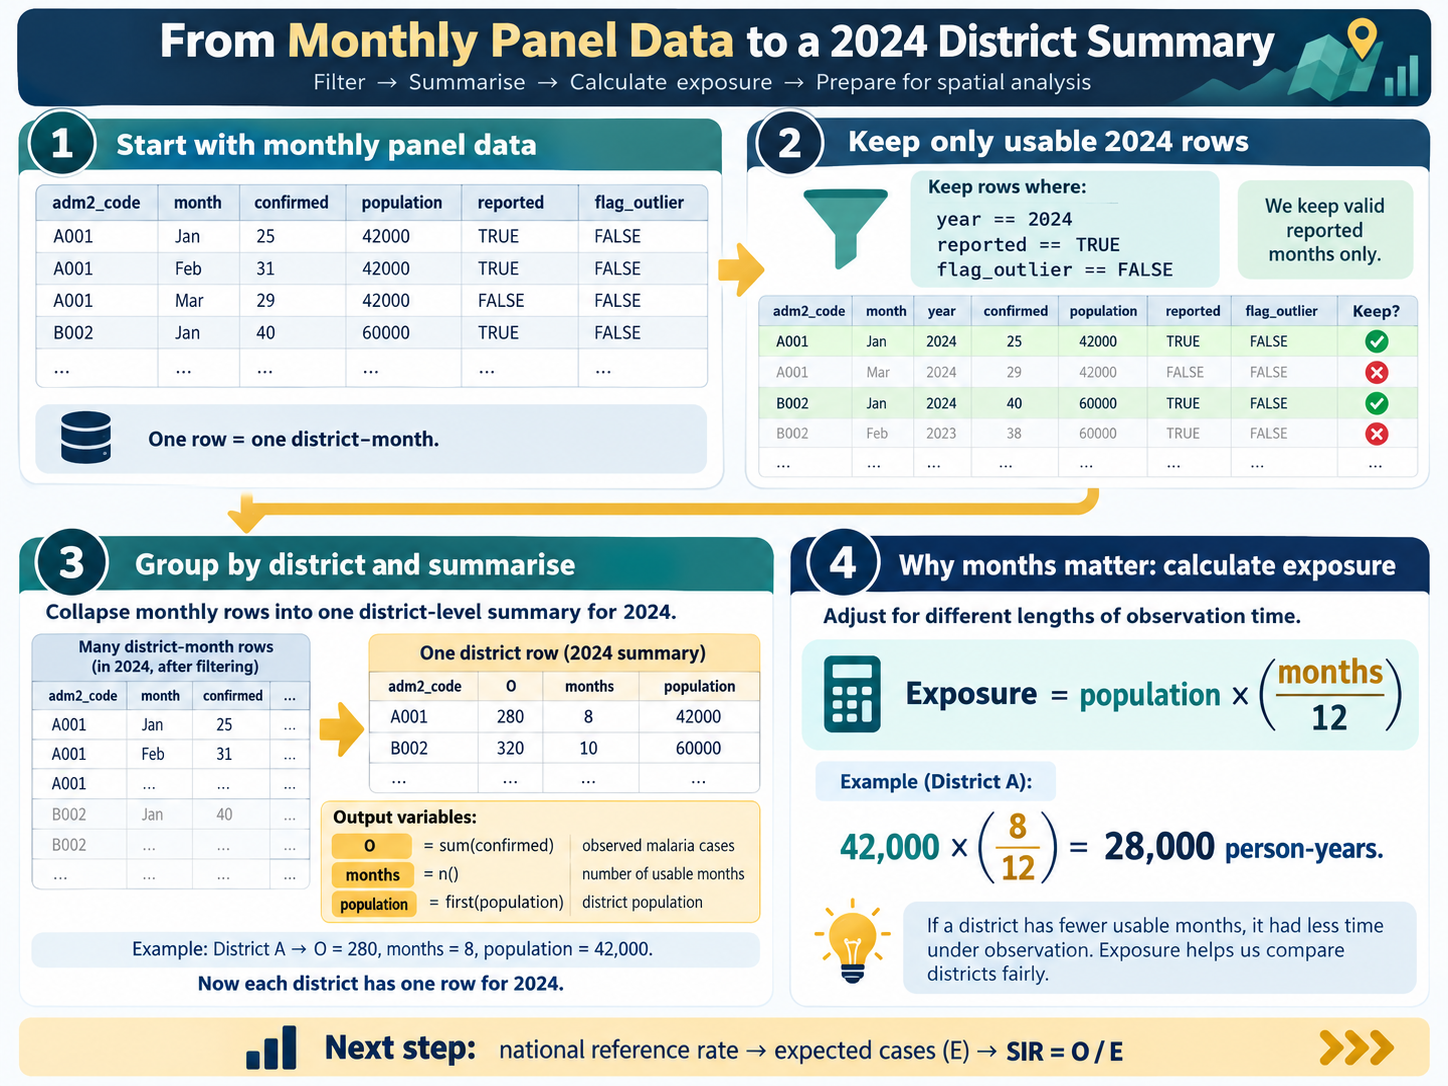

Step 1. One row per district for 2024 from the usable months.

In [ ]:
# one row per district for 2024: observed cases over the usable months, and the district characteristics
ann <- panel |> filter(year == 2024, reported, !flag_outlier) |>
  group_by(adm2_code, adm2_name, region, eco_zone) |>
  summarise(O = sum(confirmed), months = n(), population = first(population),
            rain = mean(rain_mm), tmean = mean(tmean_c), ndvi = first(ndvi), elev = first(elev_m),
            dens = first(pop_density), fac = first(fac_per_10k), .groups = "drop")
nrow(ann); table(ann$months)

All 260 districts have at least 7 usable months; 91 have all 12. The months column is the exposure adjustment used in Step 2.

### VISUAL 2 · Reference rate → expected cases → SIR

<div style="width:100%; margin:18px 0 22px; text-align:center;">
  <img src="attachment:from_district_totals_to_sir.png" alt="VISUAL 2 · Reference rate → expected cases → SIR"        width="1448" style="width:100%; max-width:1448px; height:auto; display:block; margin:auto;" />
</div>

*Illustrative learning diagram — verify real calculations with the notebook code and outputs.*

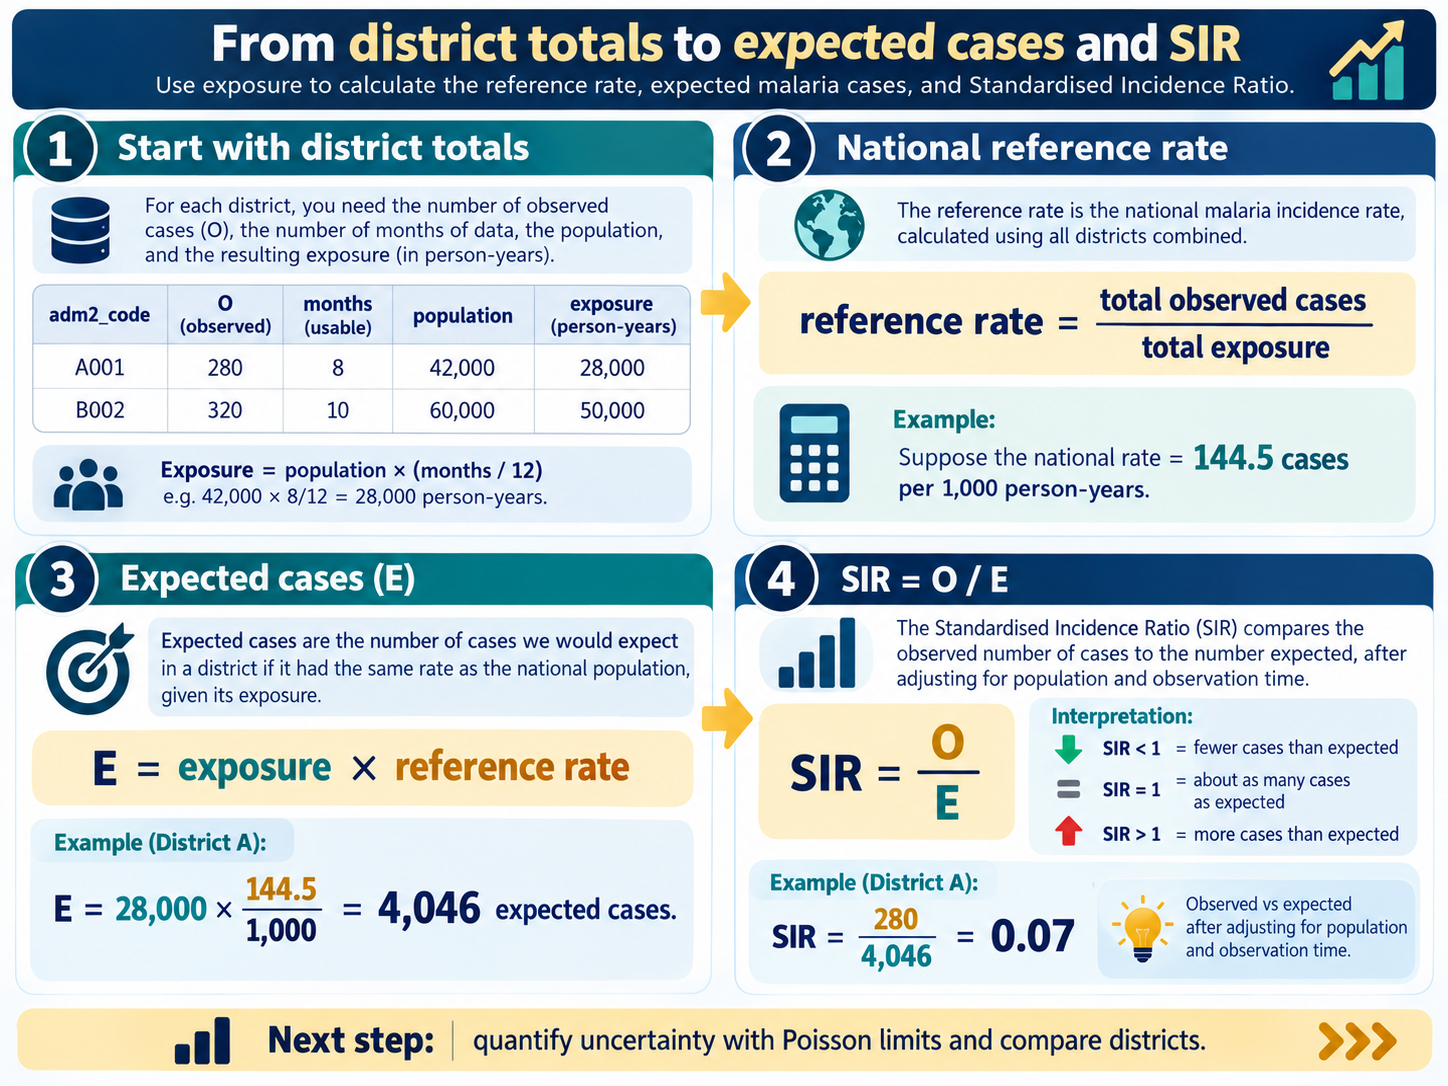

Step 2. The national rate, expected cases and the SIR.

In [ ]:
# expected cases: what each district would have if it had the national rate, allowing for months reported
rate <- sum(ann$O) / sum(ann$population * ann$months / 12)
round(rate * 1000, 1)                                         # national cases per 1,000 person-years
ann <- ann |> mutate(E = population * months / 12 * rate, SIR = O / E)
summary(ann$SIR)
ann |> arrange(-SIR) |> select(adm2_name, region, O, E, SIR, population) |> mutate(across(c(E, SIR), ~ round(.x, 2))) |> head(6)

The national rate is 144.5 per 1,000 person-years. The median district is at 0.95, close to average by construction; the top six are all in the Upper East and North East regions, with Nabdam at 2.60.

Step 3. The covariates on the scales Module 4's models read them: rainfall per 100 mm, elevation per 100 m, NDVI per 0.1, and population density on the log scale.

In [ ]:
# covariates rescaled so each rate ratio is per a meaningful step
ann <- ann |> mutate(rain100 = rain / 100, elev100 = elev / 100, ndvi10 = ndvi * 10, logdens = log(dens))
ann |> select(adm2_name, O, E, SIR, rain100, tmean, ndvi10, elev100, logdens, fac) |> mutate(across(where(is.numeric), ~ round(.x, 2))) |> head(6)

# Part B – The Forecasting Features (Module 5)

Module 5 forecasts next month's incidence for each district. A forecast may only use what is known at the end of the month it is made in, so the features are chosen by a leakage test before any model sees them.

### Visual explainer: Leakage check

*This explains what data leakage is in next-month forecasting and which variables are safe or unsafe to use.*

<div style="text-align:center; margin: 14px 0 28px 0;">
  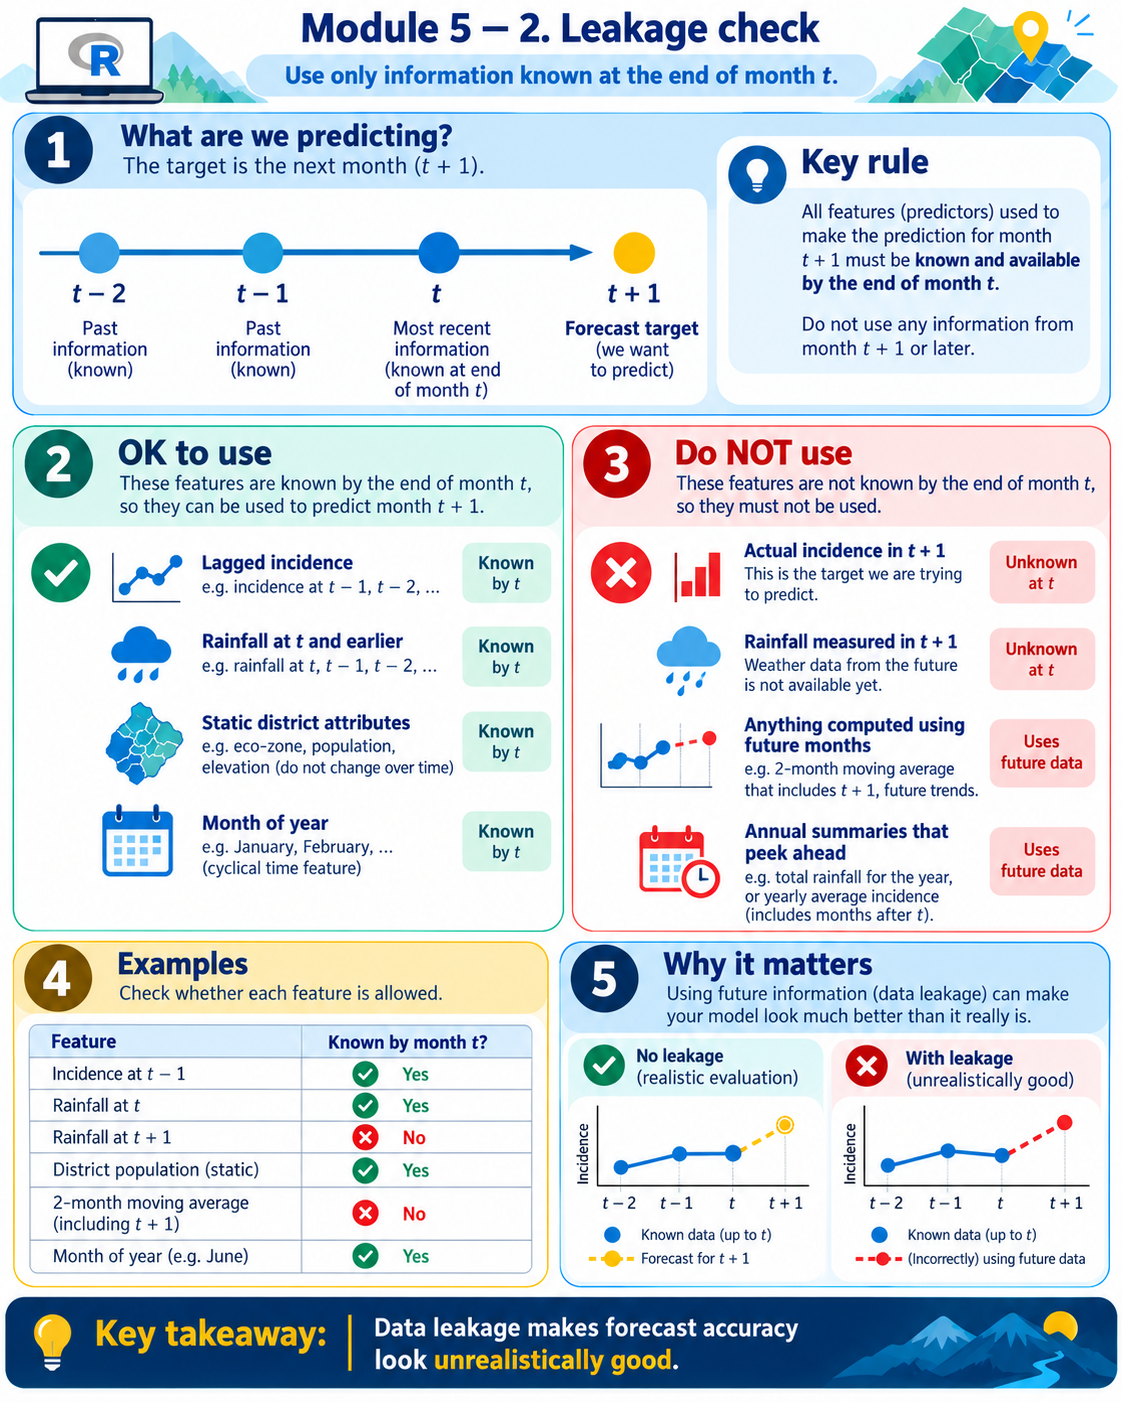
</div>


Step 1. The leakage test on the panel's columns.

In [ ]:
# the leakage test: for each column, is it known at the end of month t when predicting t + 1?
tibble(column = c("rain_mm", "tmean_c", "rain_lag1", "rain_lag2", "tmean_lag1", "cases_lag1", "reporting_rate", "elev_m / ndvi / pop_density / fac_per_10k", "month_of_year / season", "confirmed (t + 1)"),
       known_at_prediction_time = c("NO: this is next month's rainfall", "NO", "yes", "yes", "yes", "yes: last month's export", "for month t yes; for t + 1 no",
                                    "yes (static)", "yes (calendar)", "NO: the outcome")) |> print(n = 20)

Step 2. The feature set that passes the test, with the lagged case count set to missing when last month was flagged or unreported, the usable rows and the split.

In [ ]:
# the feature set that passes the test, the usable rows, and the split
model_df <- panel |>
  arrange(adm2_code, month) |> group_by(adm2_code) |>
  mutate(lag_flagged = lag(flag_outlier, 1) | !lag(reported, 1),                      # was last month itself usable?
         rate_lag1 = lag(reporting_rate, 1)) |> ungroup() |>                            # last month's reporting rate: known
  mutate(inc_lag1 = if_else(lag_flagged %in% TRUE, NA_real_, cases_lag1 / population * 1000),
         logdens = log(pop_density), elev100 = elev_m / 100, ndvi10 = ndvi * 10,
         rain_lag1_100 = rain_lag1 / 100, rain_lag2_100 = rain_lag2 / 100,
         moy = factor(month_of_year), eco_zone = factor(eco_zone), id = factor(adm2_code, levels = districts$adm2_code)) |>
  filter(reported, !flag_outlier, !is.na(inc_lag1), !is.na(rain_lag2))
model_df |> count(split)

3,330 training and 1,213 test district-months remain after requiring a usable current month, a usable previous month and two months of rainfall history. The rows lost are the price of honesty: a forecast cannot be made for a district whose last month is unknown.

## Hand-off

The two tables, saved for the modelling modules.

In [ ]:
# the hand-off folder: the model inputs, plus the panel and boundaries passed on unchanged,
# so this run is the dataset for Module 3 (which reads the panel), Module 4 and Module 5
h <- file.path(out_dir, "handoff"); dir.create(h, showWarnings = FALSE, recursive = TRUE)
write_rds(ann, file.path(h, "district_year_2024.rds"))
write_rds(model_df, file.path(h, "forecast_features.rds"))
file.copy(panel_path, file.path(h, "panel.rds"), overwrite = TRUE)
file.copy(file.path(data_dir, "ghana_districts.gpkg"), file.path(h, "ghana_districts.gpkg"), overwrite = TRUE)
dictionary <- list.files(data_dir, pattern = "^data_dictionary\\.csv$", recursive = TRUE, full.names = TRUE)
if (length(dictionary)) file.copy(dictionary[1], file.path(h, "data_dictionary.csv"), overwrite = TRUE)
# the same two tables as CSV, to read or check outside R
write_csv(ann, file.path(out_dir, "district_year_2024.csv"))
write_csv(model_df |> mutate(across(where(is.factor), as.character)), file.path(out_dir, "forecast_features.csv"))
list.files(h)

## Export for the web map viewer

Writes the map layers listed in `layers.json`.

In [ ]:
# ---- Export for the web map viewer (added by tools/prepare_notebooks.py) ----
# Each block below is wrapped in safe(): if a step was edited or skipped, the other layers are
# still written. The viewer discovers everything through layers.json.
layers <- list()
safe <- function(label, expr) tryCatch(expr, error = function(e)
  message("Export skipped - ", label, ": ", conditionMessage(e)))
add_layer <- function(...) layers[[length(layers) + 1]] <<- list(...)
wgs <- function(x) sf::st_transform(x, 4326)

# district polygons, in lon/lat, lightly simplified for the web
web_districts <- function(d, tol = 0.002) {
  d <- wgs(d)
  keep <- intersect(c("adm2_code", "adm2_name", "region", "eco_zone"), names(d))
  suppressWarnings(sf::st_simplify(d[, keep], preserveTopology = TRUE, dTolerance = tol))
}
write_geojson <- function(x, name) {
  f <- file.path(out_dir, paste0(name, ".geojson"))
  if (file.exists(f)) file.remove(f)
  x <- dplyr::mutate(x, dplyr::across(dplyr::where(is.numeric), ~ round(.x, 4)))
  sf::st_write(x, f, driver = "GeoJSON", quiet = TRUE, layer_options = "COORDINATE_PRECISION=5")
}
# long district-month table -> one column per month (inc_2024_01, ...) + field list for the slider
widen_months <- function(df, value, prefix) {
  df <- as.data.frame(df)
  d  <- data.frame(adm2_code = df$adm2_code, key = paste0(prefix, "_", format(df$month, "%Y_%m")), v = df[[value]])
  m  <- sort(unique(df$month))
  list(wide   = tidyr::pivot_wider(d, names_from = "key", values_from = "v"),
       fields = lapply(m, function(x) list(field = paste0(prefix, "_", format(x, "%Y_%m")), label = format(x, "%b %Y"))))
}
# x/y/value data frame -> heat-point JSON for the browser + a GeoTIFF for GIS users
heat_export <- function(df, name, crs = 32630, max_pts = 25000) {
  df <- df[is.finite(df$value), c("x", "y", "value")]
  tryCatch(terra::writeRaster(terra::rast(df, type = "xyz", crs = paste0("EPSG:", crs)),
                              file.path(out_dir, paste0(name, ".tif")), overwrite = TRUE),
           error = function(e) message("GeoTIFF skipped for ", name, ": ", conditionMessage(e)))
  if (nrow(df) > max_pts) df <- df[round(seq(1, nrow(df), length.out = max_pts)), ]
  ll <- sf::st_coordinates(wgs(sf::st_as_sf(df, coords = c("x", "y"), crs = crs)))
  jsonlite::write_json(list(points = data.frame(lat = ll[, 2], lng = ll[, 1], value = df$value)),
                       file.path(out_dir, paste0(name, ".heat.json")), digits = 6)
}
im_df  <- function(im) { d <- as.data.frame(im); names(d)[3] <- "value"; d }          # spatstat image
pts_df <- function(s, col) { xy <- sf::st_coordinates(s); data.frame(x = xy[, 1], y = xy[, 2], value = s[[col]]) }

# Model inputs: the 2024 district table Module 4 models, and how many usable months Module 5 has per district
safe("model inputs", {
  usable <- model_df |> dplyr::count(adm2_code, split) |>
    tidyr::pivot_wider(names_from = split, values_from = n, names_prefix = "months_", values_fill = 0)
  d <- web_districts(districts) |>
    dplyr::left_join(ann |> dplyr::select(adm2_code, O, E, SIR, months), by = "adm2_code") |>
    dplyr::left_join(usable, by = "adm2_code")
  write_geojson(d, "model_inputs")
  add_layer(id = "inputs", title = "Model inputs, 2024", kind = "choropleth", file = "model_inputs.geojson",
    fields = list(
      list(field = "SIR",          label = "SIR (observed / expected)", type = "numeric"),
      list(field = "O",            label = "Observed cases, usable months", type = "numeric"),
      list(field = "E",            label = "Expected cases at the national rate", type = "numeric"),
      list(field = "months",       label = "Usable months in 2024 (Module 4)", type = "numeric"),
      list(field = "months_train", label = "Training rows (Module 5)", type = "numeric"),
      list(field = "months_test",  label = "Test rows (Module 5)", type = "numeric"))) })

jsonlite::write_json(list(layers = layers), file.path(out_dir, "layers.json"),
                     auto_unbox = TRUE, null = "null", na = "null")
cat("Exported", length(layers), "map layer(s) to", out_dir, "\n")
print(list.files(out_dir))
